# Homework 3, Problem 4: Optimization vs Generalization

In [2]:
import numpy as np
import matplotlib.pyplot as plt

D = 4096                                # number of features = number of candidates
eta = 0.1                               # label-flip probability
informative = np.array([0, 1, 3, 7])    # informative features
weights = np.array([0.4, 0.7, 1.0, 1.4])
w_star = np.zeros(D)
w_star[informative] = weights

candidate_features = np.arange(D)       # h_j(x) = sign(x[j]), fixed in advance
Ks = 2 ** np.arange(0, 13)              # K = 1, 2, 4, ..., 4096
delta = 0.05

def sample_data(N, rng):
    """Draw N i.i.d. examples. Returns X of shape (N, D) and y in {-1, +1}^N."""
    X = rng.standard_normal((N, D))
    y = np.where(X @ w_star >= 0, 1, -1)
    flip = rng.random(N) < eta
    y[flip] *= -1
    return X, y

def population_risk(features):
    """Exact 0-1 risk of h_j(x) = sign(x[j]) for each j in `features`.

    For Gaussian X, sign(<u,X>) and sign(<v,X>) disagree with probability angle(u,v)/pi.
    A label flip turns agreement into an error, so R = eta + (1 - 2 eta) * angle / pi.
    """
    cos = w_star[features] / np.linalg.norm(w_star)
    return eta + (1 - 2 * eta) * np.arccos(cos) / np.pi

def occam_penalty(N, delta=delta):
    """eps_j = sqrt(log(2 / (pi_j * delta)) / (2N)) with pi_j = 1 / ((j+1)(j+2))."""
    j = np.arange(D)
    return np.sqrt(np.log(2 * (j + 1) * (j + 2) / delta) / (2 * N))

## (a) Empirical risk minimization
Implement the functions `empirical_risks` and `erm_select` below.

In [3]:
def empirical_risks(X, y, features):
    """0-1 empirical risk of each candidate h_j(x) = sign(x[features[j]]).

    X: (N, D) inputs, y: (N,) labels in {-1, +1}, features: (K,) int array.
    Returns a (K,) array whose j-th entry is (1/N) * sum_i 1[h_j(x_i) != y_i].
    """
    Xf = X[:, features]
    pred = np.where(Xf >= 0, 1, -1)
    return np.mean(pred != y[:, None], axis=0)


def erm_select(emp_risks, Ks):
    """For each K in Ks: the index j < K minimizing emp_risks[:K]."""
    return np.array([np.argmin(emp_risks[:K]) for K in Ks], dtype=int)


The code cell below fixes $N = 25$ and computes the empirical risk minimizer over $\mathcal{H}_K$:
$$\hat{h}_{K} \coloneqq \min_{h \in \mathcal{H}_K} \hat{\mathcal{R}}_{\mathcal{S}}(h).$$
It computes both the empirical risk $\hat{\mathcal{R}}_{\mathcal{S}}(\hat{h}_K)$ and the population risk $\mathcal{R}(\hat{h}_K)$ of $\hat{h}_K$.

This is repeated 200 times for each $K \in \{1, \ldots, 4096\}$. The average empirical risk and average population risk of $\hat{h}_K$ is plotted again $K$. 

The cell also computes the population risk minimizer 
$$h_K^* \coloneqq \min_{h \in \mathcal{H}_K} \mathcal{R}(h)$$
and plots its population risk $\mathcal{R}(h_K^*)$ against $K$. 

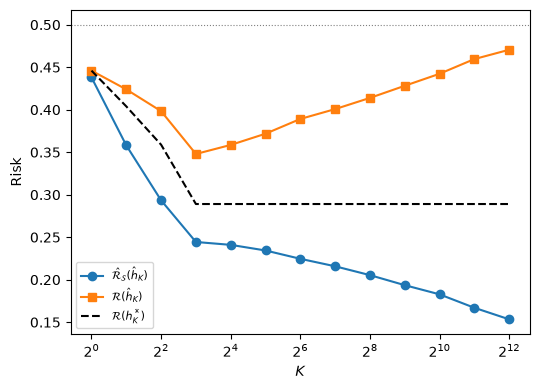

In [4]:
N = 25
trials = 200
seed = 0

rng = np.random.default_rng(seed)
pop = population_risk(candidate_features)
best_in_class = np.array([pop[:K].min() for K in Ks])   # R(h*_K)
results = {'best_in_class': best_in_class}
results['emp'] = np.zeros((trials, len(Ks)))
results['pop'] = np.zeros((trials, len(Ks)))
for t in range(trials):
    X, y = sample_data(N, rng)
    tr = empirical_risks(X, y, candidate_features)
    idx = erm_select(tr, Ks)
    results['emp'][t] = tr[idx]
    results['pop'][t] = pop[idx]    

N = 25
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(Ks, results['emp'].mean(0), 'o-', label=r'$\hat{\mathcal{R}}_{\mathcal{S}}(\hat h_K)$')
ax.plot(Ks, results['pop'].mean(0), 's-', label=r'$\mathcal{R}(\hat h_K)$')
ax.plot(Ks, results['best_in_class'], 'k--', label=r'$\mathcal{R}(h^*_K)$')
ax.axhline(0.5, color='gray', lw=0.8, ls=':')
ax.set_xscale('log', base=2)
ax.set_xlabel('$K$')
ax.set_ylabel('Risk')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('p4a.png', dpi=200)
plt.show()

## (c) Penalized empirical risk minimization

For each $K$, return the index $j < K$ minimizing $\widehat{\mathcal{R}}_\mathcal{S}(h_j) + \varepsilon_j$. You should be able to implement this in just one line using the code that you have already written in part (a).

In [ ]:
def penalized_select(emp_risks, penalties, Ks):
    """For each K in Ks: the index j < K minimizing emp_risks[j] + penalties[j]."""
    # TODO: return an int array of length len(Ks).
    raise NotImplementedError

The code cell below computes the empirical risk minimizer and the penalized empirical risk minimizer over $\mathcal{H}_K$:
$$\hat{h}_{K} \coloneqq \min_{h \in \mathcal{H}_K} \hat{\mathcal{R}}_{\mathcal{S}}(h) \qquad \qquad \hat{h}_{K}^{\rm pen} \coloneqq \min_{h \in \mathcal{H}_K} \Big\{\hat{\mathcal{R}} + \varepsilon_j \Big\}.$$
It computes the population risks $\mathcal{R}(\hat{h}_K)$ and $\mathcal{R}(\hat{h}_K^{\rm pen})$ of both $\hat{h}_K$ and $\hat{h}^{\rm pen}_K$.

This is repeated 200 times for each $K \in \{1, \ldots, 4096\}$ and $N \in \{25, 50, 100, 400\}$. The average population risks of $\hat{h}_K$ is plotted against $K$ for each $N$ on the left and the average population risk of $\hat{h}_K^{\rm pen}$ is plotted against $K$ for each $N$ on the right. 

In [ ]:
Ns = [25, 50, 100, 400]
trials = 200
seed = 0

rng = np.random.default_rng(seed)
pop = population_risk(candidate_features)
best_in_class = np.array([pop[:K].min() for K in Ks])   # R(h*_K)
results = {'best_in_class': best_in_class}
for N in Ns:
    pen = occam_penalty(N)
    out = {k: np.zeros((trials, len(Ks))) for k in ['emp', 'pop', 'pop_pen']}
    for t in range(trials):
        X, y = sample_data(N, rng)
        tr = empirical_risks(X, y, candidate_features)
        idx = erm_select(tr, Ks)
        out['emp'][t] = tr[idx]
        out['pop'][t] = pop[idx]  
        out['pop_pen'][t] = pop[penalized_select(tr, pen, Ks)]
    results[N] = out

fig, axes = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, len(Ns)))
for N, col in zip(Ns, colors):
    axes[0].plot(Ks, results[N]['pop'].mean(0), 'o-', color=col, label=f'N = {N}')
    axes[1].plot(Ks, results[N]['pop_pen'].mean(0), '^-', color=col, label=f'N = {N}')
for ax, title in zip(axes, [r'Population risks of $\hat{h}_K$',
                            r'Population risks of $\hat{h}_K^{\rm pen}$']):
    ax.plot(Ks, results['best_in_class'], 'k--', label=r'$\mathcal{R}(h^*_K)$')
    ax.set_xscale('log', base=2)
    ax.set_xlabel('$K$')
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Population risk')
fig.tight_layout()
fig.savefig('p4c.png', dpi=200)
plt.show()

## (d) Approximate optimization via early stopping
The code cell below compares the performance of empirical risk minimization with $K = 8$ against empirical risk minimization with $K = 4096$ when $N = 100$. The first column reports the empirical risks and the second column reports the population risks.

In [ ]:
i8, iK = list(Ks).index(8), len(Ks) - 1
print(f"{'emp ERM':>9} {'emp ERM':>9} | {'pop ERM':>7} {'pop ERM':>7}")
print(f"{'K=8':>9} {'K=4096':>9} | {'K=8':>7} {'K=4096':>7}")

N = 100
r = results[N]
tr, po, pp = r['emp'].mean(0), r['pop'].mean(0), r['pop_pen'].mean(0)
junk = np.mean(r['pop'][:, iK] >= 0.5 - 1e-12)   # fraction selecting an uninformative feature
print(f'{tr[i8]:9.3f} {tr[iK]:9.3f} | {po[i8]:7.3f} {po[iK]:7.3f}')